# CIFAR -10 IMages classification using CNN

## import and setup

In [ ]:
# !pip install tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn.metrics import confusion_matrix,accuracy_score

import tensorflow as tf
from tensorflow.keras import layers, models


import warnings as w
w.filterwarnings('ignore')

## 2- Load and visualize buil in data set

In [35]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

In [36]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((50000, 32, 32, 3), (50000, 1), (10000, 32, 32, 3), (10000, 1))

In [48]:
class_names =['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

## Visualize the first image 

In [49]:
X_train[0]

array([[[0.23137255, 0.24313725, 0.24705882],
        [0.16862745, 0.18039216, 0.17647059],
        [0.19607843, 0.18823529, 0.16862745],
        ...,
        [0.61960784, 0.51764706, 0.42352941],
        [0.59607843, 0.49019608, 0.4       ],
        [0.58039216, 0.48627451, 0.40392157]],

       [[0.0627451 , 0.07843137, 0.07843137],
        [0.        , 0.        , 0.        ],
        [0.07058824, 0.03137255, 0.        ],
        ...,
        [0.48235294, 0.34509804, 0.21568627],
        [0.46666667, 0.3254902 , 0.19607843],
        [0.47843137, 0.34117647, 0.22352941]],

       [[0.09803922, 0.09411765, 0.08235294],
        [0.0627451 , 0.02745098, 0.        ],
        [0.19215686, 0.10588235, 0.03137255],
        ...,
        [0.4627451 , 0.32941176, 0.19607843],
        [0.47058824, 0.32941176, 0.19607843],
        [0.42745098, 0.28627451, 0.16470588]],

       ...,

       [[0.81568627, 0.66666667, 0.37647059],
        [0.78823529, 0.6       , 0.13333333],
        [0.77647059, 0

In [50]:
X_train[0].shape

(32, 32, 3)

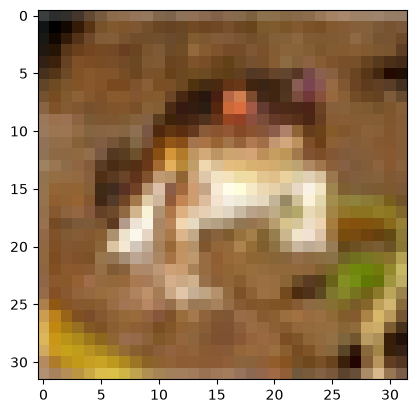

array([6], dtype=uint8)

In [51]:
plt.imshow(X_train[0])
plt.show()

y_train[0]

### visualize the multiple images 

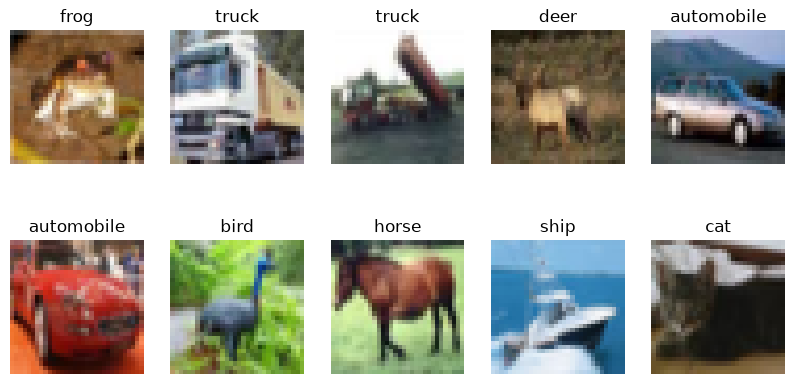

In [52]:
plt.figure(figsize=(10, 5))

for i in range(10):
  plt.subplot(2, 5, i + 1)
  plt.imshow(X_train[i])  # Note: also fixed 'X_trian' typo here if present
  plt.title(class_names[y_train[i][0]])
  plt.axis('off')

plt.show()


### Pre  Processing 

In [42]:
X_train =X_train/255
X_test =X_test/255

### Model Build compile and evaluate 

In [45]:
model=models.Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(32,32,3)),
    layers.MaxPool2D((2,2)),


    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPool2D((2,2)),


    layers.Conv2D(128,(3,3),activation='relu'),
    layers.Flatten(),




    layers.Dense(128,activation='relu'),
    layers.Dense(64,activation='relu'),
    layers.Dense(10,activation='softmax')
    
])

In [46]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [47]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 4, 4, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 364,426 (1.39 MB)

 Trainable params: 364,426 (1.39 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history=model.fit(
    X_train,y_train,
    epochs=20,
    batch_size=33,
    validation_split=0.1
)

Epoch 1/20
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 2199s 2s/step - accuracy: 0.4163 - loss: 1.5754 - val_accuracy: 0.5510 - val_loss: 1.2431
Epoch 2/20
1364/1364 ━━━━━━━━━━━━━━━━━━━━ 2296s 2s/step - accuracy: 0.5768 - loss: 1.1841 - val_accuracy: 0.6330 - val_loss: 1.0447
Epoch 3/20
 267/1364 ━━━━━━━━━━━━━━━━━━━━ 30:38 2s/step - accuracy: 0.6339 - loss: 1.0341

### Model Evaluation

In [ ]:
y_pred=model.predict(X_test)

In [ ]:
y_pred=np.argmax(y_pred,axis=1)
cm=confusion_matrix(y_test,y_pred)

In [ ]:
cm

In [ ]:
sns.heatmap(cm,annot=True,cmap='virdis')
print(f'Accuracy Score: {accuracy_score(y_test,y_pred)*100:2f}%')

### Visualize Training Process

In [ ]:
plt.figure(figsize=(14,4))
plt.plot(history.history['loss'],label='Loss')
plt.plot(history.history['val_loss'],label='Value Loss')

plt.title('Loss Score Learning graph')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(14,4))
plt.plot(history.history['Accuracy'],label='Acc')
plt.plot(history.history['val_accuracy'],label='Value Acc')

plt.title('Accuracy Score Learning graph')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### Visualize Predictions

In [ ]:
plt.figure(figsize=(16,5))
for i in range(200):
    plt.subplot(20,10,i+1)
    plt.imshow(X_test[i])
    plt.title(f"pred:{class_names[y_pred[i]]}\n"
              f"actual:{class_names[y_test[i][0]]}")
plt.axis('off')
plt.suptitle("images Classification on CIFAR:10 with 72.39% Report By :Jahanzeb Mughal")

plt.tight_layout()
plt.savefig('report.png')
plt.show()